<center><h1>Liang_Qian_HW2</h1></center>
<br>
<br>

Name: Qian Liang
<br> 
Github Username: 9681620075
<br>
USC ID: qliang21-77

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [63]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from statsmodels.stats.outliers_influence\
    import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm


Get the Cycle Power Plant Data Set

In [64]:
df=pd.read_excel('Folds5x2_pp.xlsx', sheet_name=0)
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [65]:
print(df.columns)

Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='str')


### (b) Exploring the data

#### i. rows and columns

In [66]:
print(df.shape)

(9568, 5)


- 9568 rows and 5 columns.
- Rows represent the hourly observations
- columns [AT,V,AP,RH] represent 4 features , column [PE] represent 1 target/response

#### ii. pairwise scatterplots of all the varianbles

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

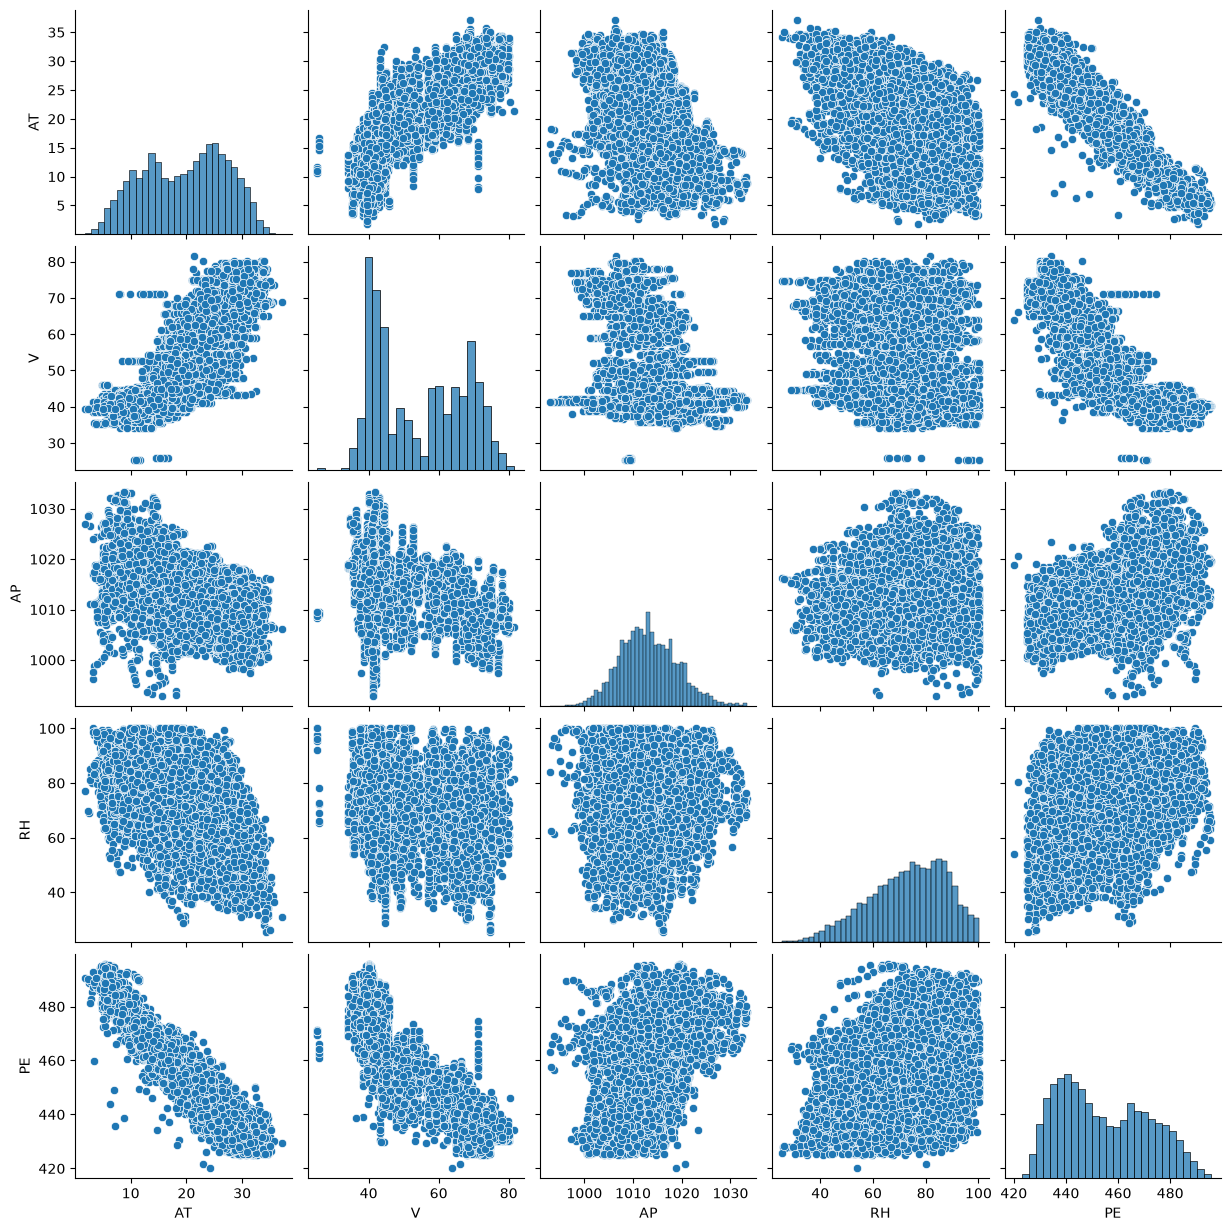

In [68]:
sns.pairplot(df)
plt.show()

# From the graph:
- AT,V shows negative relationship with PE.
- AP, RH does not show a strong relationship with PE as the data points are more clustered.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [69]:
df.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


### (c) Simple Linear Regression

In [70]:
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from statsmodels.stats.outliers_influence import OLSInfluence

In [71]:
df.columns

Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='str')

AT~PE
From the summary below: p-value = 0 < 0.05, showing there is a statistically significant association bewtween AT and PE.
The relationship is negative as coef is -2.1713
There are outliers spreading below the regression line.

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:11   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.0

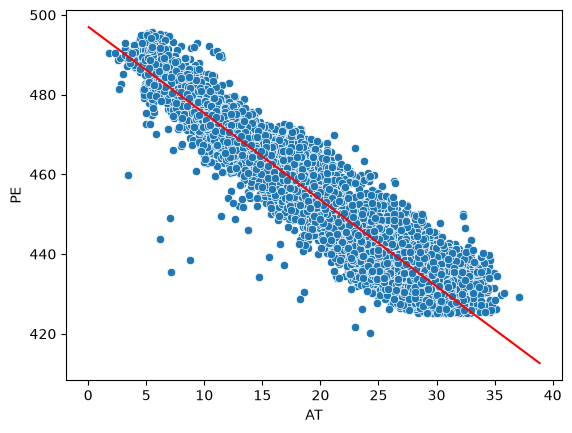

In [72]:
# AT~PE
x_AT=df[['AT']]
x_AT_sm = sm.add_constant(x_AT)
y=df[['PE']]
model = sm.OLS(y,x_AT_sm)
results = model.fit()

print(results.summary())
def abline(ax, slope, intercept):
    xlim = np.array(ax.get_xlim())
    ylim = intercept + slope * xlim
    ax.plot(xlim, ylim,color ='red')
ax = sns.scatterplot(data=df, x='AT',y='PE')
abline(ax, results.params['AT'], results.params['const'])
plt.show()
   

V~PE
From the summary below: p-value = 0 < 0.05, showing there is a statistically significant association bewtween V and PE
The relationship is negative as coef is -1.1681
There are outliers spreading below and above when V=70 the regression line.

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                 2.972e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:11   Log-Likelihood:                -33963.
No. Observations:                9568   AIC:                         6.793e+04
Df Residuals:                    9566   BIC:                         6.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        517.8015      0.378   1370.218      0.0

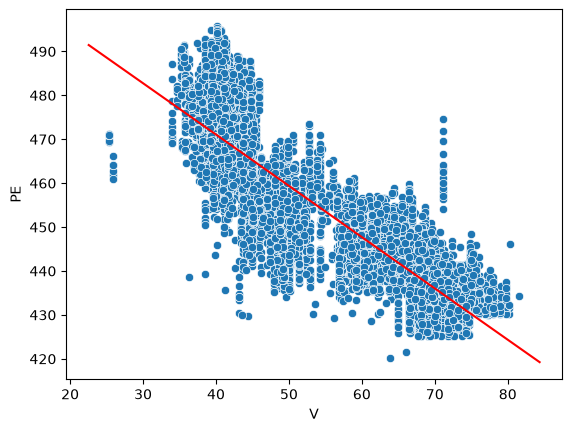

In [73]:
# V~PE
x_V=df[['V']]
x_V_sm = sm.add_constant(x_V)
y=df[['PE']]
model = sm.OLS(y,x_V_sm)
results = model.fit()

print(results.summary())
def abline(ax, slope, intercept):
    xlim = np.array(ax.get_xlim())
    ylim = intercept + slope * xlim
    ax.plot(xlim, ylim,color ='red')
ax = sns.scatterplot(data=df, x='V',y='PE')
abline(ax, results.params['V'], results.params['const'])
plt.show()

AP~PE

From the summary below: p-value = 0 < 0.05, showing there is a statistically significant association bewtween AP and PE.
The relationship is positive as coef is 1.4899 .
There are outliers spreading above the regression line.

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.269
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     3516.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:11   Log-Likelihood:                -39224.
No. Observations:                9568   AIC:                         7.845e+04
Df Residuals:                    9566   BIC:                         7.847e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1055.2610     25.459    -41.449      0.0

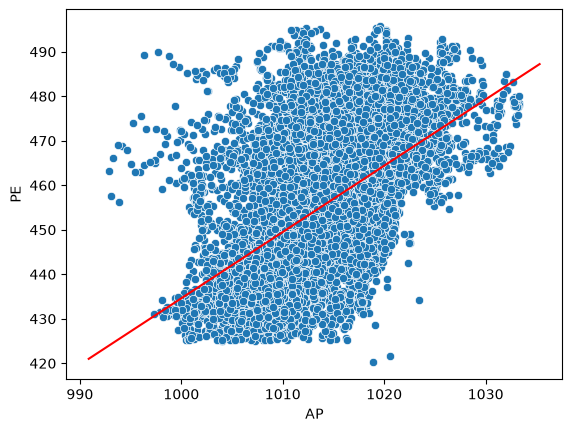

In [74]:
# AP~PE
x_AP=df[['AP']]
x_AP_sm = sm.add_constant(x_AP)
y=df[['PE']]
model = sm.OLS(y,x_AP_sm)
results = model.fit()

print(results.summary())
def abline(ax, slope, intercept):
    xlim = np.array(ax.get_xlim())
    ylim = intercept + slope * xlim
    ax.plot(xlim, ylim,color ='red')
ax = sns.scatterplot(data=df, x='AP',y='PE')
abline(ax, results.params['AP'], results.params['const'])
plt.show()

RH~PE

From the summary below: p-value = 0 < 0.05, showing there is a statistically significant association bewtween RH and PE.
The relationship is positive as coef is  0.4557 .
There are outliers spreading above the regression line.

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     1714.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:11   Log-Likelihood:                -39933.
No. Observations:                9568   AIC:                         7.987e+04
Df Residuals:                    9566   BIC:                         7.988e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        420.9618      0.823    511.676      0.0

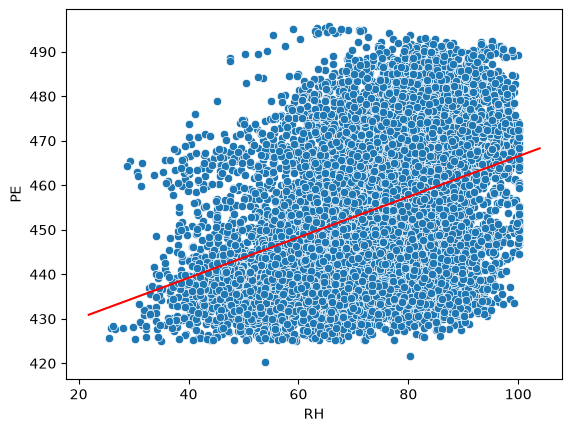

In [75]:
# RH~PE
x_RH=df[['RH']]
x_RH_sm = sm.add_constant(x_RH)
y=df[['PE']]
model = sm.OLS(y,x_RH_sm)
results = model.fit()

print(results.summary())
def abline(ax, slope, intercept):
    xlim = np.array(ax.get_xlim())
    ylim = intercept + slope * xlim
    ax.plot(xlim, ylim,color ='red')
ax = sns.scatterplot(data=df, x='RH',y='PE')
abline(ax, results.params['RH'], results.params['const'])
plt.show()

### (d) Multiple Regression

In [76]:
x_multiple = df[['AT', 'V', 'AP', 'RH']]
y_multiple = df[['PE']]
x_multiple_sm = sm.add_constant(x_multiple)
model = sm.OLS(y_multiple,x_multiple_sm)
results = model.fit()

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

From the summary above, AT,V,AP,RH can reject the null hypothesis, since the p-value are all estimated to be 0 and less than 0.05, showing there is a statistical significance of the multiple regression. 

### (e) 1c Compare to 1d

In [77]:
coe=pd.DataFrame({
    'features':['AT','V','AP','RH'],
    'single_coe':[-2.1713, -1.1681,1.4899 , 0.4557 ],
    'multi_coe':[-1.9775,-0.2339,0.0621,-0.1581  ]
}).set_index('features')
coe

,single_coe,multi_coe
features,,
AT,-2.1713,-1.9775
V,-1.1681,-0.2339
AP,1.4899,0.0621
RH,0.4557,-0.1581


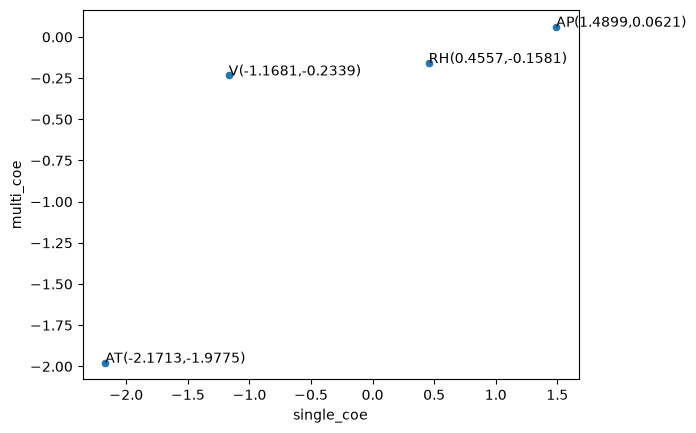

In [78]:
sns.scatterplot(data=coe, x='single_coe',y='multi_coe')
for i in range(len(coe)):
    x = coe['single_coe'].iloc[i]
    y= coe['multi_coe'].iloc[i]

    plt.annotate(
        f"{coe.index[i]}({x:.4f},{y:.4f})", (x,y)
    )
plt.show()

For Comparison: 
AT: single regression coefficient is smaller and more negative than multi regression coefficent
V: single regression coefficient is smaller and more negative than multi regression coefficent
RH: single regression coefficient is smaller and becomes negative compare to multi regression coefficent
AP: single regression coefficient is much larger than multi regression coefficent

### (f) Nonlinear Association

From the summary below, there are non-linear associations between AT and PE as the P values for x,x^2 and x^3 are estimated to 0.

In [79]:
# AT~PE
x_AT=df['AT']
x_AT_poly = pd.DataFrame({
    'AT':x_AT,
    'AT^2':x_AT**2,
    'AT^3':x_AT**3})
x_AT_poly_sm = sm.add_constant(x_AT_poly)
y=df[['PE']]
model = sm.OLS(y,x_AT_poly_sm)
results = model.fit()

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                 3.299e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -29101.
No. Observations:                9568   AIC:                         5.821e+04
Df Residuals:                    9564   BIC:                         5.824e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        492.7281      0.673    732.248      0.0

From the summary below, there are non-linear associations between V and PE as the P values for x and x^3 are estimated to 0. However, for x^2, the p value is 0.768 > 0.05, which cannot reject the null hypothesis. 

In [80]:
# V~PE
x_V=df['V']
x_V_poly = pd.DataFrame({
    'V':x_V,
    'V^2':x_V**2,
    'V^3':x_V**3})
x_V_poly_sm = sm.add_constant(x_V_poly)
y=df[['PE']]
model = sm.OLS(y,x_V_poly_sm)
results = model.fit()

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                 1.098e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -33585.
No. Observations:                9568   AIC:                         6.718e+04
Df Residuals:                    9564   BIC:                         6.721e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        554.1468      9.151     60.557      0.0

From the summary below, there are non-linear associations between AP and PE as the P values for x,x^2 and x^3 are estimated to 0.

In [81]:
# AP~PE
x_AP=df['AP']
x_AP_poly = pd.DataFrame({
    'AP':x_AP,
    'AP^2':x_AP**2,
    'AP^3':x_AP**3})
x_AP_poly_sm = sm.add_constant(x_AP_poly)
y=df[['PE']]
model = sm.OLS(y,x_AP_poly_sm)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.275
Method:                 Least Squares   F-statistic:                     1813.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -39184.
No. Observations:                9568   AIC:                         7.837e+04
Df Residuals:                    9565   BIC:                         7.840e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0747      0.009      8.415      0.0

From the summary below, there are non-linear associations between RH and PE as the P values for x,x^2 and x^3 are estimated to 0.

In [82]:
# RH~PE
x_RH=df['RH']
x_RH_poly = pd.DataFrame({
    'RH':x_RH,
    'RH^2':x_RH**2,
    'RH^3':x_RH**3})
x_RH_poly_sm = sm.add_constant(x_RH_poly)
y=df[['PE']]
model = sm.OLS(y,x_RH_poly_sm)
results = model.fit()

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.153
Method:                 Least Squares   F-statistic:                     579.2
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -39923.
No. Observations:                9568   AIC:                         7.985e+04
Df Residuals:                    9564   BIC:                         7.988e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        468.4135     10.545     44.422      0.0

### (g) Interactions of Predictors

In [83]:
x_AT=df['AT']
x_V=df['V']
x_AP=df['AP']
x_RH=df['RH']
x_pair = pd.DataFrame({
    'AT':x_AT,
    'V':x_V,
    'AP':x_AP,
    'RH':x_RH,
    'AT-V':x_AT*x_V,
    'AT-AP':x_AT*x_AP,
    'AT-RH':x_AT*x_RH,
    'V-AP':x_V*x_AP,
    'V-RH':x_V*x_RH,
    'AP-RH':x_AP*x_RH,
    })
x_pair_sm = sm.add_constant(x_pair)
y=df[['PE']]
model = sm.OLS(y,x_pair_sm)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        685.7825     78.640      8.721      0.0

Frome summary above: 
AT-V,AT-AP,AT-RH,V-AP,AP-RH all thave p-values less than 0.05, showing there is statistically significance between the interactions

### (h) Improvement

In [84]:
#split data 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
x = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']
x_train,x_test,y_train,y_test= train_test_split(x,y, test_size=0.3,random_state =42)

In [85]:
x_sm = sm.add_constant(x_train)
model = sm.OLS(y_train,x_sm)
results = model.fit()
#train MSE
y_train_pred = results.predict(x_sm)
train_mse = mean_squared_error(y_train, y_train_pred)
#test MSE
x_test_sm = sm.add_constant(x_test)
y_test_pred = results.predict(x_test_sm)
test_mse = mean_squared_error(y_test,y_test_pred)

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 2.194e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -19630.
No. Observations:                6697   AIC:                         3.927e+04
Df Residuals:                    6692   BIC:                         3.930e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        467.8414     11.502     40.673      0.0

In [86]:
print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Train MSE: 20.580839725738695
Test MSE: 21.23985693822525


In [87]:
#train random 70% 
t_x_AT=x_train['AT']
t_x_V=x_train['V']
t_x_AP=x_train['AP']
t_x_RH=x_train['RH']
t_x_pair = pd.DataFrame({
    'AT':t_x_AT,
    'V':t_x_V,
    'AP':t_x_AP,
    'RH':t_x_RH,
    'AT-V':t_x_AT*t_x_V,
    'AT-AP':t_x_AT*t_x_AP,
    'AT-RH':t_x_AT*t_x_RH,
    'V-AP':t_x_V*t_x_AP,
    'V-RH':t_x_V*t_x_RH,
    'AP-RH':t_x_AP*t_x_RH,
    'AT**2':t_x_AT**2,
    'V**2':t_x_V**2,
    'AP**2':t_x_AP**2,
    'RH**2':t_x_RH**2
    })
train_x_pair_sm = sm.add_constant(t_x_pair)

model = sm.OLS(y_train,train_x_pair_sm)
results_train = model.fit()

print(results_train.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     7272.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:12   Log-Likelihood:                -19160.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6682   BIC:                         3.845e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7664.9809   1429.568     -5.362      0.0

 remove v-ap;at-ap;v-rh;v^2 because these interactions have p-value greater than 0.05, showing not statistically significant

In [88]:
#test random 70% 
test_x_AT=x_test['AT']
test_x_V=x_test['V']
test_x_AP=x_test['AP']
test_x_RH=x_test['RH']
test_x_pair = pd.DataFrame({
    'AT':test_x_AT,
    'V':test_x_V,
    'AP':test_x_AP,
    'RH':test_x_RH,
    'AT-V':test_x_AT*test_x_V,
    'AT-AP':test_x_AT*test_x_AP,
    'AT-RH':test_x_AT*test_x_RH,
    'V-AP':test_x_V*test_x_AP,
    'V-RH':test_x_V*test_x_RH,
    'AP-RH':test_x_AP*test_x_RH,
    'AT**2':test_x_AT**2,
    'V**2':test_x_V**2,
    'AP**2':test_x_AP**2,
    'RH**2':test_x_RH**2
    })
test_x_pair_sm = sm.add_constant(test_x_pair)

In [89]:

# Train MSE
y_train_pred1 = results_train.predict(train_x_pair_sm)
train_mse1 = mean_squared_error(y_train, y_train_pred1)

# Test MSE
y_test_pred1 = results_train.predict(test_x_pair_sm)
test_mse1 = mean_squared_error(y_test, y_test_pred1)

print("Full Interaction & Quadratic Regression Train MSE:", train_mse1)
print("Full Interaction & Quadratic Regression Test MSE:", test_mse1)

Full Interaction & Quadratic Regression Train MSE: 17.887799616633345
Full Interaction & Quadratic Regression Test MSE: 18.64731247858121


In [90]:
# remove
# v-ap;at-ap;v-rh;v^2

In [91]:
#reduced model 
r_x_AT=x_train['AT']
r_x_V=x_train['V']
r_x_AP=x_train['AP']
r_x_RH=x_train['RH']
r_x_pair = pd.DataFrame({
    'AT':r_x_AT,
    'V':r_x_V,
    'AP':r_x_AP,
    'RH':r_x_RH,
    'AT-V':r_x_AT*r_x_V,
    #'AT-AP':r_x_AT*r_x_AP,
    'AT-RH':r_x_AT*r_x_RH,
    #'V-AP':r_x_V*r_x_AP,
    #'V-RH':r_x_V*r_x_RH,
    'AP-RH':r_x_AP*r_x_RH,
    'AT**2':r_x_AT**2,
    #'V**2':r_x_V**2,
    'AP**2':r_x_AP**2,
    'RH**2':r_x_RH**2
    })
reduce_x_pair_sm = sm.add_constant(r_x_pair)

model = sm.OLS(y_train,reduce_x_pair_sm)
results_reduce = model.fit()

print(results_reduce.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                 1.017e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:39:13   Log-Likelihood:                -19166.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6686   BIC:                         3.843e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.046e+04   1091.512     -9.581      0.0

In [92]:
#reduced test model
rt_x_AT=x_test['AT']
rt_x_V=x_test['V']
rt_x_AP=x_test['AP']
rt_x_RH=x_test['RH']
rt_x_pair = pd.DataFrame({
    'AT':rt_x_AT,
    'V':rt_x_V,
    'AP':rt_x_AP,
    'RH':rt_x_RH,
    'AT-V':rt_x_AT*rt_x_V,
    #'AT-AP':rt_x_AT*rt_x_AP,
    'AT-RH':rt_x_AT*rt_x_RH,
    #'V-AP':rt_x_V*rt_x_AP,
    #'V-RH':rt_x_V*rt_x_RH,
    'AP-RH':rt_x_AP*rt_x_RH,
    'AT**2':rt_x_AT**2,
    #'V**2':rt_x_V**2,
    'AP**2':rt_x_AP**2,
    'RH**2':rt_x_RH**2
    })
reduce_test_x_pair_sm = sm.add_constant(rt_x_pair)


In [93]:
#train MSE
y_train_pred3 = results_reduce.predict(reduce_x_pair_sm)
train_mse3 = mean_squared_error(y_train, y_train_pred3)
#test MSE
y_test_pred3 = results_reduce.predict(reduce_test_x_pair_sm)
test_mse3 = mean_squared_error(y_test,y_test_pred3)

print("Reduced Train MSE:", train_mse3)
print("Reduced Test MSE:", test_mse3)

Reduced Train MSE: 17.9178126711853
Reduced Test MSE: 18.6943461908097


### (i) KNN

In [94]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

In [95]:
scaler = MinMaxScaler()
x_normalized_train_data = scaler.fit_transform(x_train)
x_normalized_test_data = scaler.transform(x_test)

In [96]:
#raw feature
test_mse = {}
train_mse ={}
for k in range (1,101):
    knn =  KNeighborsRegressor(n_neighbors =k)
    knn_pred_test = knn.fit(x_train,y_train).predict(x_test)
    knn_pred_train = knn.fit(x_train,y_train).predict(x_train)
    test_mse[k] = mean_squared_error(y_test, knn_pred_test)
    train_mse[k] = mean_squared_error(y_train, knn_pred_train)
mse_df = pd.DataFrame({'test_mse' :test_mse, 'train_mse':train_mse})
min_mse = mse_df['test_mse'].min()
best_k = mse_df[mse_df['test_mse']==min_mse]
print(best_k)

   test_mse  train_mse
5  15.72682  10.600769


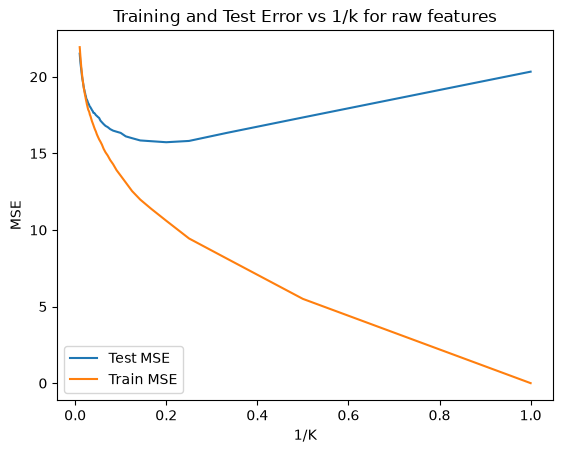

In [97]:
k_inverse=[1/k for k in range(1,101)]
plt.plot(k_inverse,mse_df['test_mse'], label='Test MSE')
plt.plot(k_inverse, mse_df['train_mse'], label='Train MSE')
plt.xlabel('1/K')
plt.ylabel('MSE')
plt.legend()
plt.title('Training and Test Error vs 1/k for raw features')
plt.show()

In [98]:
# Normalized Data
normalize_test_mse = {}
normalize_train_mse ={}
for k in range (1,101):
    knn =  KNeighborsRegressor(n_neighbors =k)
    knn_pred_test = knn.fit(x_normalized_train_data,y_train).predict(x_normalized_test_data)
    knn_pred_train = knn.fit(x_normalized_train_data,y_train).predict(x_normalized_train_data)
    normalize_test_mse[k] = mean_squared_error(y_test, knn_pred_test)
    normalize_train_mse[k] = mean_squared_error(y_train, knn_pred_train)
normalize_mse_df = pd.DataFrame({'normalize_test_mse' :normalize_test_mse, 'normalize_train_mse':normalize_train_mse})
normalize_min_mse = normalize_mse_df['normalize_test_mse'].min()
normalize_best_k = normalize_mse_df[normalize_mse_df['normalize_test_mse']==normalize_min_mse]
print(normalize_best_k)

   normalize_test_mse  normalize_train_mse
4           14.291333             8.454348


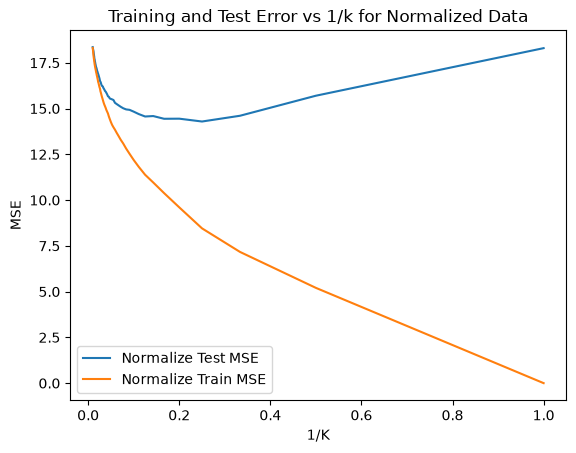

In [99]:
k_inverse=[1/k for k in range(1,101)]
plt.plot(k_inverse,normalize_mse_df['normalize_test_mse'], label='Normalize Test MSE')
plt.plot(k_inverse, normalize_mse_df['normalize_train_mse'], label='Normalize Train MSE')
plt.xlabel('1/K')
plt.ylabel('MSE')
plt.legend()
plt.title('Training and Test Error vs 1/k for Normalized Data')
plt.show()

In [100]:
print('Optimal k* and Minimum test, train MSE with raw features:')
print()
print(best_k)
print()
print('Optimal k* for Minimum test, train MSE with normalized data:')
print()
print(normalize_best_k)


Optimal k* and Minimum test, train MSE with raw features:

   test_mse  train_mse
5  15.72682  10.600769

Optimal k* for Minimum test, train MSE with normalized data:

   normalize_test_mse  normalize_train_mse
4           14.291333             8.454348


### (j ) Compare KNN and Linear

In [101]:
summary_all = pd.DataFrame({
    'Methods': [
         'Lienar Regression without Interaction',
        'Full Interaction & Quadratic Regression', 
        'Reduced Interaction & Quadratic Regression',
        'KNN Normalized',
        'KNN Raw Feature'
    ],
    'MSE Test Error': [21.23985693822525,
        18.64731247858121,
                        18.6943461908097,
                        14.291333,
                        15.72682 
  
    ],
    'MSE Train Error': [20.580839725738695,
        17.887799616633345,
                        17.9178126711853,
                        8.454348,
                        10.600769
 ]
}).set_index('Methods').sort_values('MSE Test Error')

summary_all

,MSE Test Error,MSE Train Error
Methods,,
KNN Normalized,14.291333,8.454348
KNN Raw Feature,15.726820,10.600769
Full Interaction & Quadratic Regression,18.647312,17.887800
Reduced Interaction & Quadratic Regression,18.694346,17.917813
Lienar Regression without Interaction,21.239857,20.580840


KNN normalized has smallest MSE test errors as KNN is sensitive to the scale of the predictors, normalization will adjust the scale of the features for equal impact. 

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

## Large sample size with small number of p meaning more stable model which large data points supporting predictors. More flexibility would perform better which could avoid underfitting. 

### (b) The number of predictors p is extremely large, and the number of observations n is small.

# Inflexible model would work better to avoid overfitting and better intreprete the relationship of x and y. 

### (c) The relationship between the predictors and response is highly non-linear.

## More flexible is better because it can fit complicated models and captures low bias and high variance data. 
## Inflexible model will cause underfitting of the data. 

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

## If the variance is extremenly high, it is better to use less flexible model to trade off with low bias.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [102]:
import math


In [103]:

obs1= math.sqrt(0**2+3**2+0**2)
obs2=math.sqrt(2**2+0**2+0**2)
obs3= math.sqrt(0**2+1**2+3**2)
obs4=math.sqrt(0**2+1**2+2**2)
obs5= math.sqrt((-1)**2+0**2+1**2)
obs6=math.sqrt(1**2+1**2+1**2)

In [104]:
data = pd.DataFrame({
    'Obs':[1,2,3,4,5,6],
    'X1':[0,2,0,0,-1,1],
    'X2':[3,0,1,1,0,1],
    'X3':[0,0,3,2,1,1],
    'Y':['Red','Red','Red','Green','Green','Red'],
    'Distance':[obs1,obs2,obs3,obs4,obs5,obs6]
}).set_index('Obs')
data

,X1,X2,X3,Y,Distance
Obs,,,,,
1,0,3,0,Red,3.000000
2,2,0,0,Red,2.000000
3,0,1,3,Red,3.162278
4,0,1,2,Green,2.236068
5,-1,0,1,Green,1.414214
6,1,1,1,Red,1.732051


### (b) What is our prediction with K = 1? Why?

# Best prediction of K=1 is Green. Looking at nearest 1 neighbor, obs5's distance from (0,0,0) is the closest and the classified as green.

### (c) What is our prediction with K = 3? Why?

# Best prediction of K=3 is Red. Looking at nearest 3 neighbor, obs2, obs5 and obs6 and 2 out of the 3 neighbors are classified as red. 

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

# If Bayes decision boundry is highly non-linear, we would expect best value of K to be smaller. Smaller k is highly flexible with low bias and high variance. With highly felxible model, prediction is more likely to be affected by the nearby data points and resulting the graph to be more curved and complex. 

Reference:
- https://www.statology.org/matplotlib-abline/
- https://learner-cares.medium.com/handy-python-pandas-for-data-normalization-and-scaling-9658846de8fc